# 03: Boundary model: BiLSTM over frozen embeddings vs. the baseline

**Hypothesis:** a BiLSTM trained on thousands of real chapterings beats the unsupervised TextTiling baseline (02) at locating boundaries.

**Shipping rule** (0009 §7): the BiLSTM ships only if it beats the baseline on **validation F1@5s** in the **product setting** (~6 chapters/h). The oracle-count results are reported too, because the creators' references are much denser than "few and broad" (see 02).

Settings fixed by 02 (preliminary, 300 English videos):
- **Encoder: `e5-small`.** It ties MiniLM (F1@5s 10.8 vs 10.9); e5-small is chosen for its MIT licence.
- **Unit: `sentence`** (2–15 s). It has the highest ceiling: F1@5s 83.3 / F1@3s 72.8, against 70.8 / 47.2 for `block10`. The baseline differences between units were marginal.

Data: `01_data` → `interim/{train,val,es_val}.jsonl`. Section 2 below is also the **official baseline run on our validation split**. It uses the same units and encoder, so `02_baseline.ipynb` is not re-run on `val`; the preliminary 02 already settled units and encoder. Test sets (`test`, `es_test`) are **not touched** until `05_eval`.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from dotenv import load_dotenv
load_dotenv('../.env')
from lib import data as d, runs as rundirs, vidchapters as vc
from lib.units import UnitConfig
from lib.encode import Encoder
from lib.store import Store
from lib.build_store import build_store
from lib.baseline import boundary_scores
from lib.decoding import DecodeConfig
from lib.train import TrainConfig, train, evaluate_scores, evaluate_store, predict_scores
from lib.model import BoundaryTagger

ROOT = d.data_root()
ENCODER, UNIT = 'e5-small', UnitConfig(mode='sentence', min_s=2, max_s=15)
STORES = ROOT / 'embeddings' / f'{ENCODER}-sentence'
RUN = Path(rundirs.run_dir('boundaries')); RUN.mkdir(parents=True, exist_ok=True)
CKPT = ROOT / 'checkpoints' / 'boundaries'
PRODUCT = DecodeConfig(per_hour=6, min_len_s=60)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE, STORES)

cuda /home/pablo/yts-experiments/m5-chapters/embeddings/e5-small-sentence


## 1. Encode train / val / es_val once (cached on the second drive)

In [2]:
enc = None
for split in ('train', 'val', 'es_val'):
    if (STORES / split / 'index.json').exists():
        print(split, 'cached'); continue
    enc = enc or Encoder(ENCODER, device=DEVICE)
    videos = list(vc.load_jsonl(ROOT / f'interim/{split}.jsonl'))
    t0 = time.time(); n = build_store(videos, enc, UNIT, STORES / split)
    print(f'{split}: {len(videos)} videos, {n} units, {time.time()-t0:.0f}s')
del enc; torch.cuda.empty_cache()
stores = {s: Store(STORES / s) for s in ('train', 'val', 'es_val')}
pd.DataFrame([dict(split=s, videos=len(st), units=int(sum(v['n'] for v in st.videos)),
                   positives_per_video=np.mean([len(v['labels']) for v in st.videos]),
                   units_per_positive=sum(v['n'] for v in st.videos) / max(1, sum(len(v['labels']) for v in st.videos)))
              for s, st in stores.items()]).set_index('split').round(1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1997.56it/s]

  64/9112 videos, 26149 units


  512/9112 videos, 218396 units


  960/9112 videos, 408180 units


  1408/9112 videos, 609319 units


... (21 outputs left out)

val: 900 videos, 349835 units, 68s


  18/18 videos, 2694 units


es_val: 18 videos, 2694 units, 1s


,videos,units,positives_per_video,units_per_positive
split,,,,
train,9112,3591173,9.6,41.1
val,900,349835,9.8,39.5
es_val,18,2694,7.1,21.2


## 2. The bar to beat: the baseline over these same units

In [3]:
WINDOW = 10  # units ≈ 60 s with ~6 s sentences (best/near-best in 02)
base = lambda e, m: boundary_scores(e, window=WINDOW)
baseline = {}
for s in ('val', 'es_val'):
    for oracle in (False, True):
        baseline[s, oracle] = evaluate_scores(base, stores[s], PRODUCT, oracle)
pd.DataFrame(baseline).T.rename_axis(['split', 'oracle'])[['F1@5s', 'F1@3s', 'F1@30s', 'tIoU-F1', 'Pk', 'WindowDiff', 'count_MAE']]

F1@5s  F1@3s  F1@30s  tIoU-F1     Pk  WindowDiff  count_MAE
split  oracle                                                              
val    False    7.770  5.364  20.845   12.519  0.423       0.439      6.837
       True    11.518  7.938  34.212   20.965  0.420       0.447      0.711
es_val False   10.311  5.650  20.168   11.989  0.401       0.409      5.500
       True    15.735  9.149  38.073   23.369  0.349       0.372      0.556

## 3. BiLSTM training

A few configurations, 10 epochs each. The best epoch is kept by **validation F1@5s (product setting)**.

In [4]:
CONFIGS = {
    'default': TrainConfig(),
    'pos5': TrainConfig(pos_weight=5.0),
    'pos20': TrainConfig(pos_weight=20.0),
    'big': TrainConfig(proj=384, hidden=256),
}
runs = {}
for name, cfg in CONFIGS.items():
    print('=== ', name, cfg)
    t0 = time.time()
    runs[name] = train(stores['train'], stores['val'], cfg, CKPT / name, DEVICE, PRODUCT)
    print(f'{name}: {time.time()-t0:.0f}s, best epoch {runs[name]["best"]["epoch"]}, F1@5s {runs[name]["best"]["F1@5s"]}')

===  default TrainConfig(epochs=10, batch_size=16, lr=0.001, weight_decay=0.0001, pos_weight=10.0, neighbour_weight=0.3, max_units=2000, proj=256, hidden=128, layers=2, dropout=0.2, seed=0)


{"epoch": 1, "train_loss": 1.1918158397339937, "sec": 158.3, "F1@3s": 2.807, "F1@5s": 4.586, "P@5s": 8.248, "R@5s": 3.176, "F1@10s": 7.844, "F1@30s": 18.89, "tIoU-F1": 9.49, "mean_tIoU": 46.696, "Pk": 0.409, "WindowDiff": 0.433, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 7.394, "oracle_F1@3s": 4.761, "oracle_tIoU-F1": 13.811}


{"epoch": 2, "train_loss": 1.0565016284323576, "sec": 161.1, "F1@3s": 6.182, "F1@5s": 8.732, "P@5s": 15.84, "R@5s": 6.027, "F1@10s": 13.267, "F1@30s": 22.169, "tIoU-F1": 13.43, "mean_tIoU": 50.926, "Pk": 0.404, "WindowDiff": 0.424, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 12.748, "oracle_F1@3s": 9.157, "oracle_tIoU-F1": 21.914}


{"epoch": 3, "train_loss": 0.9549848926171922, "sec": 158.8, "F1@3s": 10.185, "F1@5s": 13.507, "P@5s": 23.812, "R@5s": 9.427, "F1@10s": 19.022, "F1@30s": 27.162, "tIoU-F1": 14.996, "mean_tIoU": 52.565, "Pk": 0.39, "WindowDiff": 0.41, "count_MAE": 6.838, "pred_chapters_mean": 5.079, "ref_chapters_mean": 11.252, "oracle_F1@5s": 18.232, "oracle_F1@3s": 13.862, "oracle_tIoU-F1": 25.435}


{"epoch": 4, "train_loss": 0.9022898930206633, "sec": 153.5, "F1@3s": 10.337, "F1@5s": 13.73, "P@5s": 24.21, "R@5s": 9.582, "F1@10s": 19.433, "F1@30s": 27.756, "tIoU-F1": 15.495, "mean_tIoU": 53.077, "Pk": 0.383, "WindowDiff": 0.403, "count_MAE": 6.838, "pred_chapters_mean": 5.079, "ref_chapters_mean": 11.252, "oracle_F1@5s": 18.96, "oracle_F1@3s": 14.101, "oracle_tIoU-F1": 25.447}


{"epoch": 5, "train_loss": 0.8530458774482995, "sec": 160.0, "F1@3s": 11.411, "F1@5s": 14.747, "P@5s": 25.626, "R@5s": 10.352, "F1@10s": 20.552, "F1@30s": 29.017, "tIoU-F1": 16.465, "mean_tIoU": 53.872, "Pk": 0.376, "WindowDiff": 0.396, "count_MAE": 6.838, "pred_chapters_mean": 5.079, "ref_chapters_mean": 11.252, "oracle_F1@5s": 20.467, "oracle_F1@3s": 15.648, "oracle_tIoU-F1": 27.835}


... (31 outputs left out)

{"epoch": 7, "train_loss": 0.8151638291645469, "sec": 159.8, "F1@3s": 12.759, "F1@5s": 16.255, "P@5s": 27.685, "R@5s": 11.505, "F1@10s": 21.481, "F1@30s": 29.782, "tIoU-F1": 17.384, "mean_tIoU": 54.574, "Pk": 0.371, "WindowDiff": 0.392, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.55, "oracle_F1@3s": 16.732, "oracle_tIoU-F1": 28.983}


{"epoch": 8, "train_loss": 0.8056582077814821, "sec": 147.8, "F1@3s": 12.898, "F1@5s": 16.623, "P@5s": 28.166, "R@5s": 11.791, "F1@10s": 22.427, "F1@30s": 31.069, "tIoU-F1": 18.318, "mean_tIoU": 55.394, "Pk": 0.364, "WindowDiff": 0.385, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.76, "oracle_F1@3s": 16.682, "oracle_tIoU-F1": 30.13}


{"epoch": 9, "train_loss": 0.7962917492055056, "sec": 154.8, "F1@3s": 12.966, "F1@5s": 16.517, "P@5s": 28.372, "R@5s": 11.649, "F1@10s": 22.506, "F1@30s": 31.263, "tIoU-F1": 18.261, "mean_tIoU": 55.437, "Pk": 0.362, "WindowDiff": 0.383, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.771, "oracle_F1@3s": 16.74, "oracle_tIoU-F1": 30.221}


{"epoch": 10, "train_loss": 0.7909414407192615, "sec": 164.7, "F1@3s": 12.976, "F1@5s": 16.641, "P@5s": 28.419, "R@5s": 11.765, "F1@10s": 22.676, "F1@30s": 31.45, "tIoU-F1": 18.369, "mean_tIoU": 55.528, "Pk": 0.362, "WindowDiff": 0.382, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.843, "oracle_F1@3s": 16.716, "oracle_tIoU-F1": 30.488}
big: 1542s, best epoch 10, F1@5s 16.641


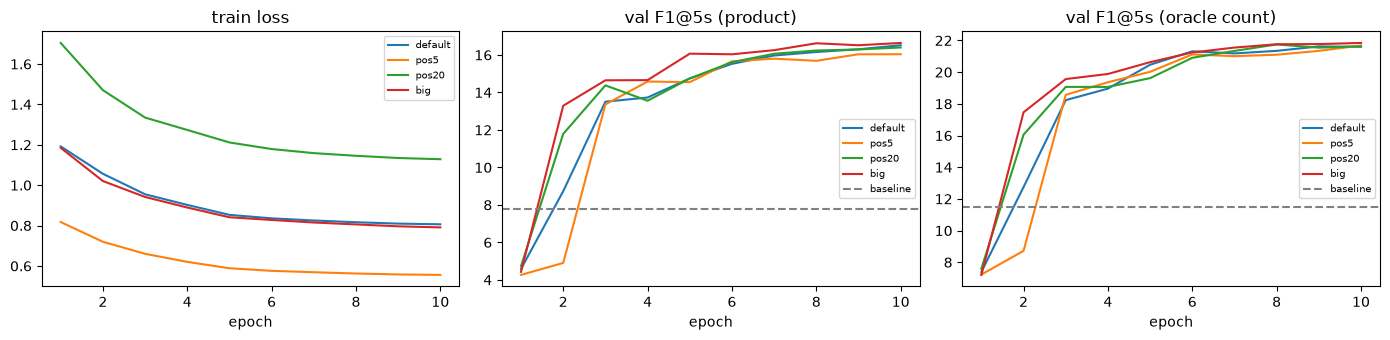

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for name, r in runs.items():
    h = pd.DataFrame(r['history'])
    ax[0].plot(h.epoch, h.train_loss, label=name); ax[1].plot(h.epoch, h['F1@5s'], label=name); ax[2].plot(h.epoch, h['oracle_F1@5s'], label=name)
for a, t, key in zip(ax, ('train loss', 'val F1@5s (product)', 'val F1@5s (oracle count)'), (None, (False,), (True,))):
    a.set_title(t); a.set_xlabel('epoch')
    if key: a.axhline(baseline['val', key[0]]['F1@5s'], color='grey', ls='--', label='baseline')
    a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RUN / 'learning_curves.png', dpi=110); plt.show()

## 4. Best model vs. baseline: English validation and **Spanish** (cross-lingual transfer)

In [6]:
best_name = max(runs, key=lambda n: runs[n]['best']['F1@5s'])
ck = torch.load(CKPT / best_name / 'best.pt')
model = BoundaryTagger(**ck['model_config']); model.load_state_dict(ck['state_dict']); model.to(DEVICE)
rows = []
for s in ('val', 'es_val'):
    for oracle in (False, True):
        rows.append(dict(split=s, oracle=oracle, method='baseline', **baseline[s, oracle]))
        rows.append(dict(split=s, oracle=oracle, method=f'bilstm:{best_name}', **evaluate_store(model, stores[s], DEVICE, PRODUCT, oracle)))
cmp = pd.DataFrame(rows)
cmp[['split', 'oracle', 'method', 'F1@5s', 'F1@3s', 'F1@30s', 'tIoU-F1', 'mean_tIoU', 'Pk', 'WindowDiff', 'count_MAE']]

,split,oracle,method,F1@5s,F1@3s,F1@30s,tIoU-F1,mean_tIoU,Pk,WindowDiff,count_MAE
0,val,False,baseline,7.770,5.364,20.845,12.519,50.109,0.423,0.439,6.837
1,val,False,bilstm:big,16.641,12.976,31.450,18.369,55.528,0.362,0.382,6.837
2,val,True,baseline,11.518,7.938,34.212,20.965,56.316,0.420,0.447,0.711
3,val,True,bilstm:big,21.843,16.716,44.594,30.488,62.876,0.335,0.368,0.702
4,es_val,False,baseline,10.311,5.650,20.168,11.989,50.326,0.401,0.409,5.500
5,es_val,False,bilstm:big,7.424,5.256,20.792,10.966,51.563,0.350,0.364,5.500
6,es_val,True,baseline,15.735,9.149,38.073,23.369,59.100,0.349,0.372,0.556
7,es_val,True,bilstm:big,10.258,4.967,36.426,23.745,59.317,0.351,0.400,0.556


In [7]:
val_p = cmp[(cmp.split == 'val') & ~cmp.oracle].set_index('method')['F1@5s']
ships = val_p[f'bilstm:{best_name}'] > val_p['baseline']
print(f'Shipping rule, val F1@5s (product): BiLSTM {val_p[f"bilstm:{best_name}"]:.2f} vs baseline {val_p["baseline"]:.2f} -> '
      + ('BiLSTM ships' if ships else 'BASELINE ships'))

Shipping rule, val F1@5s (product): BiLSTM 16.64 vs baseline 7.77 -> BiLSTM ships


## 5. Examples: scores from both methods on one English and one Spanish video

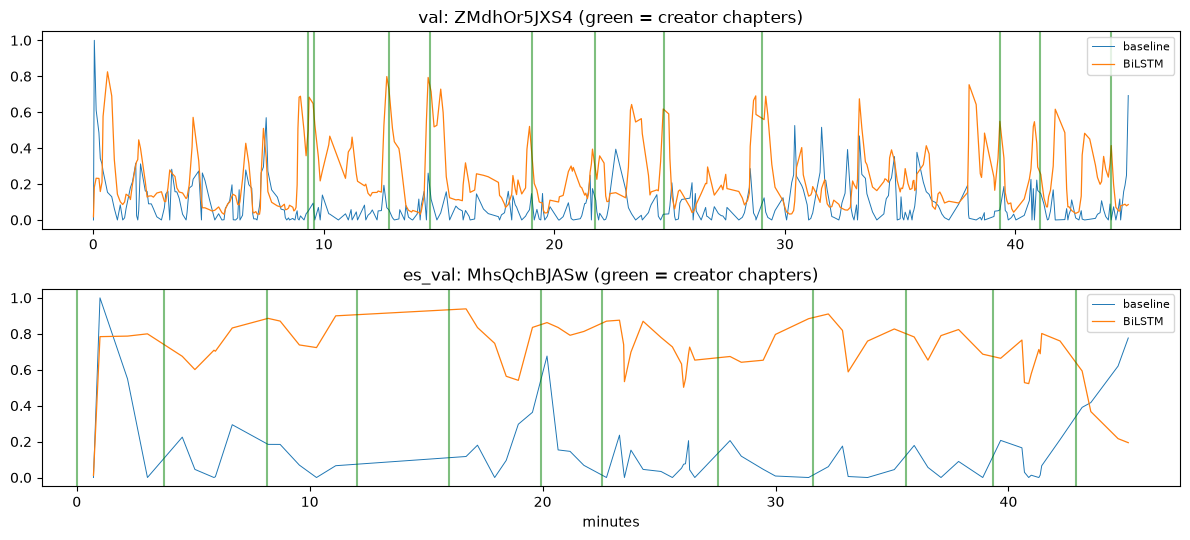

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5))
for ax, s in zip(axes, ('val', 'es_val')):
    st = stores[s]; i = int(np.argmin([abs(v['duration'] - 45 * 60) for v in st.videos]))
    e, m = st.get(i); t = np.array(m['unit_starts']) / 60
    ax.plot(t, boundary_scores(e, window=WINDOW), lw=.7, label='baseline')
    ax.plot(t, predict_scores(model, e, m['unit_starts'], m['duration'], DEVICE), lw=.9, label='BiLSTM')
    for c in m['chapter_starts']: ax.axvline(c / 60, color='green', alpha=.5)
    ax.set_title(f'{s}: {m["vid"]} (green = creator chapters)'); ax.legend(fontsize=8)
axes[-1].set_xlabel('minutes'); plt.tight_layout(); plt.savefig(RUN / 'examples.png', dpi=110); plt.show()

In [9]:
json.dump(dict(encoder=ENCODER, unit=UNIT.__dict__, decode_product=PRODUCT.__dict__, baseline_window_units=WINDOW,
               configs={k: v.__dict__ for k, v in CONFIGS.items()}), open(RUN / 'config.json', 'w'), indent=1)
json.dump(dict(best=best_name, best_epoch=runs[best_name]['best']['epoch'], bilstm_ships=bool(ships),
               comparison=json.loads(cmp.to_json(orient='records')),
               histories={k: r['history'] for k, r in runs.items()}), open(RUN / 'metrics.json', 'w'), indent=1)
print('saved to', RUN)

saved to runs/2026-11-07-rtx5070-boundaries
